# Exercise 2 – CNN Baseline and MLP Comparison

Train the three-layer CNN baseline on CIFAR-10 using the same split and training settings as Exercise 1. Use validation loss to save a best-validation checkpoint; use the official test set only after training to report the final and early-stopped models.

## 1. CNNs for image classification

Convolutions learn local patterns with shared weights, so a feature detector can recognize an edge or texture at different image positions. Pooling reduces spatial size and provides some tolerance to small shifts. Stacked layers can combine edges into textures and object parts. An MLP instead flattens the image and uses dense weights, which do not directly preserve local neighborhoods.

## 2. Shared setup and reproducibility

This notebook uses the same seed-42 split, normalization, batch size, epoch count, optimizer, and learning rate as Exercises 1 and 4. CIFAR-10 is downloaded only if its local folder is missing.

In [1]:
import json
import sys
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import Markdown, display
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
print("Python:", sys.executable)
DATA_DIR = PROJECT_ROOT / "data"
CIFAR_DIR = DATA_DIR / "cifar-10-batches-py"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "exercise_2"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DOWNLOAD_DATA = not CIFAR_DIR.exists()
print("Project:", PROJECT_ROOT)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Python: D:\AI ML\AI-ML-assessment-cifar10-project\.venv\Scripts\python.exe
Project: D:\AI ML\AI-ML-assessment-cifar10-project
Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


## 3. Preprocessing, split, and loaders

The exact same seeded permutation is used in Exercises 1 and 4. The official test partition is not loaded here. A dedicated generator fixes the shuffled training order.

In [2]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)
BATCH_SIZE = 64
EPOCHS = 20
LEARNING_RATE = 1e-3
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
train_val_dataset = datasets.CIFAR10(
    root=str(DATA_DIR), train=True, download=DOWNLOAD_DATA, transform=transform
)
assert len(train_val_dataset) == 50_000
split_indices = torch.randperm(
    50_000, generator=torch.Generator().manual_seed(42)
).tolist()
train_dataset = Subset(train_val_dataset, split_indices[:45_000])
val_dataset = Subset(train_val_dataset, split_indices[45_000:])
loader_args = {"batch_size": BATCH_SIZE, "num_workers": 0, "pin_memory": DEVICE.type == "cuda"}
train_loader = DataLoader(
    train_dataset, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), **loader_args,
)
train_eval_loader = DataLoader(train_dataset, shuffle=False, **loader_args)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_args)
CLASS_NAMES = train_val_dataset.classes
print(f"Training: {len(train_dataset):,}; validation: {len(val_dataset):,}")


Training: 45,000; validation: 5,000


## 4. Three-layer CNN baseline

Two 3×3 convolutions use 32 and 64 filters. ReLU and 2×2 max pooling follow each convolution. A 32×32 image becomes an 8×8 feature map, so the final Linear layer maps 4,096 features to ten classes. The model has exactly three trainable layers and 60,362 parameters.


In [3]:
class CIFAR10CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(64 * 8 * 8, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        return self.fc(self.flatten(x))

model = CIFAR10CNN().to(DEVICE)
trainable_layers = [m for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
assert len(trainable_layers) == 3
TRAINABLE_PARAMETERS = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert TRAINABLE_PARAMETERS == 60_362
print(model)
print("Trainable layers:", len(trainable_layers))
print("Trainable parameters:", f"{TRAINABLE_PARAMETERS:,}")


CIFAR10CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc): Linear(in_features=4096, out_features=10, bias=True)
)
Trainable layers: 3
Trainable parameters: 60,362


## 5. Training, validation, and best-validation-loss checkpoint

The epoch loop is shared with the width baseline in Exercise 4. Training and validation loss and accuracy are recorded every epoch. The best checkpoint is selected by validation loss only; the test set is not involved.

In [4]:
criterion = nn.CrossEntropyLoss()

def epoch_metrics(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum = 0.0
    correct = 0
    sample_count = 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, labels in loader:
            try:
                images = images.to(DEVICE, non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)
                if training:
                    optimizer.zero_grad(set_to_none=True)
                logits = model(images)
                loss = criterion(logits, labels)
                if training:
                    loss.backward()
                    optimizer.step()
                n = labels.size(0)
                sample_count += n
                loss_sum += loss.item() * n
                correct += (logits.argmax(1) == labels).sum().item()
            except torch.cuda.OutOfMemoryError as exc:
                if training:
                    optimizer.zero_grad(set_to_none=True)
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
                raise RuntimeError(
                    "CUDA out of memory. Run stopped without retry. Reduce BATCH_SIZE, recreate the model and optimizer, then restart."
                ) from exc
    return loss_sum / sample_count, correct / sample_count

def evaluate(model, loader, collect_predictions=False):
    model.eval()
    loss_sum = 0.0
    correct = 0
    sample_count = 0
    y_true, y_pred = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            logits = model(images)
            loss = criterion(logits, labels)
            n = labels.size(0)
            sample_count += n
            loss_sum += loss.item() * n
            predictions = logits.argmax(1)
            correct += (predictions == labels).sum().item()
            if collect_predictions:
                y_true.extend(labels.cpu().tolist())
                y_pred.extend(predictions.cpu().tolist())
    metrics = (loss_sum / sample_count, correct / sample_count)
    return (*metrics, y_true, y_pred) if collect_predictions else metrics

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
history = {key: [] for key in ("train_loss", "train_accuracy", "val_loss", "val_accuracy")}
best_val_loss = float("inf")
best_val_loss_epoch = None
BEST_CHECKPOINT = ARTIFACT_DIR / "cnn_baseline_best_val_loss.pth"
training_start = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    train_loss, train_accuracy = epoch_metrics(model, train_loader, optimizer)
    val_loss, val_accuracy = epoch_metrics(model, val_loader)
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_val_loss_epoch = epoch
        torch.save(model.state_dict(), BEST_CHECKPOINT)
    print(
        f"Epoch {epoch}/{EPOCHS} | train loss {train_loss:.4f}, train accuracy {train_accuracy:.4f} | "
        f"val loss {val_loss:.4f}, val accuracy {val_accuracy:.4f} | best val loss {best_val_loss:.4f} (epoch {best_val_loss_epoch})"
    )
training_seconds = time.perf_counter() - training_start
print(f"Training time: {training_seconds:.1f} seconds")


Epoch 1/20 | train loss 1.3196, train accuracy 0.5347 | val loss 1.0738, val accuracy 0.6226 | best val loss 1.0738 (epoch 1)


Epoch 2/20 | train loss 0.9764, train accuracy 0.6604 | val loss 0.9738, val accuracy 0.6640 | best val loss 0.9738 (epoch 2)


Epoch 3/20 | train loss 0.8476, train accuracy 0.7063 | val loss 0.8985, val accuracy 0.6908 | best val loss 0.8985 (epoch 3)


Epoch 4/20 | train loss 0.7583, train accuracy 0.7392 | val loss 0.8850, val accuracy 0.6964 | best val loss 0.8850 (epoch 4)


Epoch 5/20 | train loss 0.6918, train accuracy 0.7626 | val loss 0.8843, val accuracy 0.7056 | best val loss 0.8843 (epoch 5)


Epoch 6/20 | train loss 0.6389, train accuracy 0.7816 | val loss 0.8441, val accuracy 0.7144 | best val loss 0.8441 (epoch 6)


... (10 outputs left out)

Epoch 17/20 | train loss 0.3058, train accuracy 0.8920 | val loss 1.2306, val accuracy 0.6834 | best val loss 0.8440 (epoch 7)


Epoch 18/20 | train loss 0.2853, train accuracy 0.8981 | val loss 1.2782, val accuracy 0.6868 | best val loss 0.8440 (epoch 7)


Epoch 19/20 | train loss 0.2710, train accuracy 0.9025 | val loss 1.2746, val accuracy 0.6884 | best val loss 0.8440 (epoch 7)


Epoch 20/20 | train loss 0.2592, train accuracy 0.9088 | val loss 1.3634, val accuracy 0.6786 | best val loss 0.8440 (epoch 7)
Training time: 268.8 seconds


## 6. Learning curves and final evaluation-mode metrics

Plot the training history, then evaluate the final-epoch model on the complete training and validation subsets in evaluation mode. These clean metrics are distinct from the online training metrics recorded each epoch.

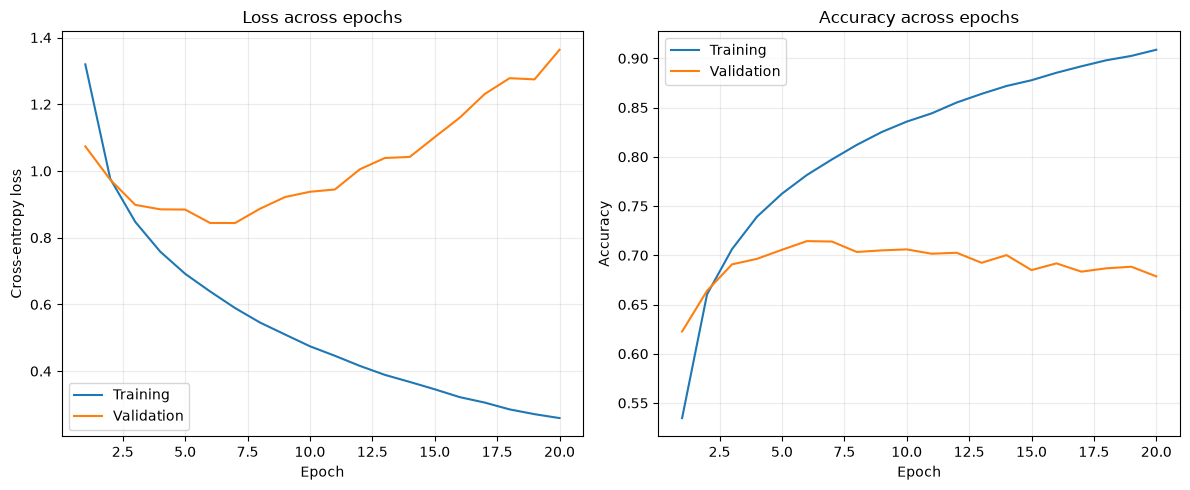

Final-epoch eval-mode train: loss=0.2271, accuracy=0.9209
Final-epoch validation: loss=1.3634, accuracy=0.6786


In [5]:
epochs = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(epochs, history["train_loss"], label="Training")
axes[0].plot(epochs, history["val_loss"], label="Validation")
axes[0].set(title="Loss across epochs", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[0].legend(); axes[0].grid(alpha=0.25)
axes[1].plot(epochs, history["train_accuracy"], label="Training")
axes[1].plot(epochs, history["val_accuracy"], label="Validation")
axes[1].set(title="Accuracy across epochs", xlabel="Epoch", ylabel="Accuracy")
axes[1].legend(); axes[1].grid(alpha=0.25)
fig.tight_layout(); fig.savefig(ARTIFACT_DIR / "learning_curves.png", dpi=160); plt.show()
final_train_loss, final_train_accuracy = evaluate(model, train_eval_loader)
final_val_loss, final_val_accuracy = evaluate(model, val_loader)
print("Final-epoch eval-mode train:", f"loss={final_train_loss:.4f}, accuracy={final_train_accuracy:.4f}")
print("Final-epoch validation:", f"loss={final_val_loss:.4f}, accuracy={final_val_accuracy:.4f}")


## 7. Final and early-stopped baseline evaluation

Only after training is complete, load the official test set. Evaluate the final-epoch model and the checkpoint selected by lowest validation loss. Test results are reported, not used to select either model.

Final-epoch official test loss: 1.3832
Final-epoch official test accuracy: 0.6850 (68.50%)


Early-stopped checkpoint: epoch 7, selected by validation loss
Early-stopped official test loss: 0.8596
Early-stopped official test accuracy: 0.7143 (71.43%)
              precision    recall  f1-score   support

    airplane       0.68      0.75      0.71      1000
  automobile       0.83      0.76      0.80      1000
        bird       0.53      0.61      0.57      1000
         cat       0.56      0.43      0.48      1000
        deer       0.56      0.76      0.65      1000
         dog       0.66      0.56      0.61      1000
        frog       0.77      0.74      0.75      1000
       horse       0.75      0.71      0.73      1000
        ship       0.80      0.78      0.79      1000
       truck       0.76      0.75      0.76      1000

    accuracy                           0.69     10000
   macro avg       0.69      0.68      0.68     10000
weighted avg       0.69      0.69      0.68     10000



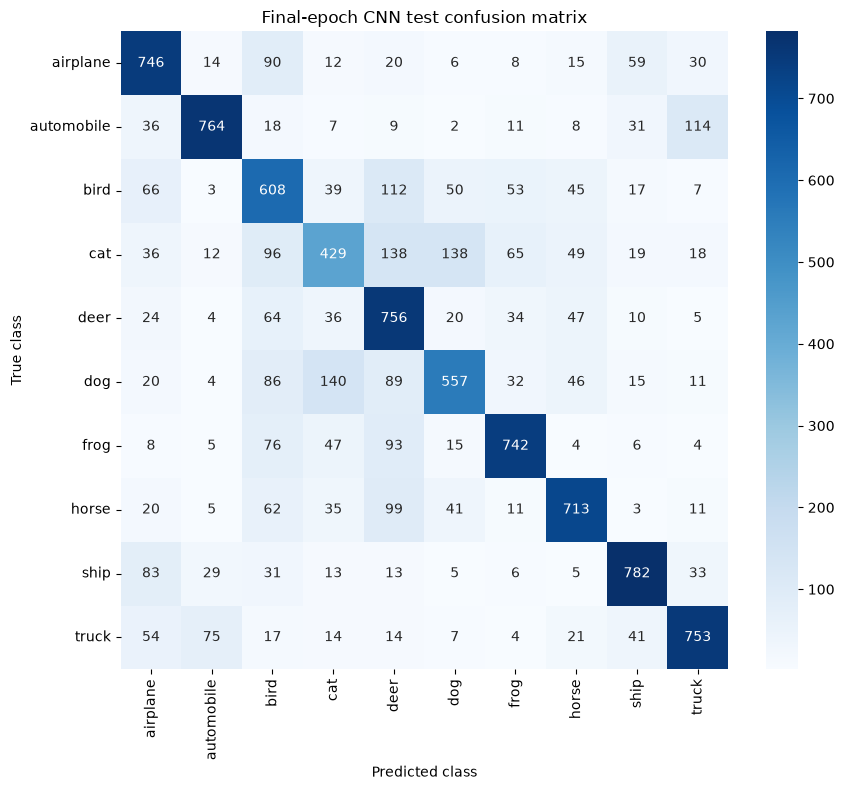

In [6]:
test_dataset = datasets.CIFAR10(
    root=str(DATA_DIR), train=False, download=DOWNLOAD_DATA, transform=transform
)
assert len(test_dataset) == 10_000
test_loader = DataLoader(test_dataset, shuffle=False, **loader_args)
final_test_loss, final_test_accuracy, y_true, y_pred = evaluate(model, test_loader, collect_predictions=True)
print(f"Final-epoch official test loss: {final_test_loss:.4f}")
print(f"Final-epoch official test accuracy: {final_test_accuracy:.4f} ({100 * final_test_accuracy:.2f}%)")

best_model = CIFAR10CNN().to(DEVICE)
best_model.load_state_dict(torch.load(BEST_CHECKPOINT, map_location=DEVICE, weights_only=True))
best_train_loss, best_train_accuracy = evaluate(best_model, train_eval_loader)
best_val_loss_eval, best_val_accuracy = evaluate(best_model, val_loader)
best_test_loss, best_test_accuracy = evaluate(best_model, test_loader)
print(f"Early-stopped checkpoint: epoch {best_val_loss_epoch}, selected by validation loss")
print(f"Early-stopped official test loss: {best_test_loss:.4f}")
print(f"Early-stopped official test accuracy: {best_test_accuracy:.4f} ({100 * best_test_accuracy:.2f}%)")
report_text = classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0)
report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
print(report_text)
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set(xlabel="Predicted class", ylabel="True class", title="Final-epoch CNN test confusion matrix")
fig.tight_layout(); fig.savefig(ARTIFACT_DIR / "test_confusion_matrix.png", dpi=160); plt.show()


## 8. Save checkpoints and measured results

The primary baseline is the final-epoch model. The second checkpoint is selected using validation loss only and is labeled the early-stopped baseline.

In [7]:
FINAL_CHECKPOINT = ARTIFACT_DIR / "cnn_baseline_final_epoch.pth"
torch.save(model.cpu().state_dict(), FINAL_CHECKPOINT)
torch.save(model.state_dict(), ARTIFACT_DIR / "cnn_baseline.pth")
model.to(DEVICE)
final_metrics = {
    "train": {"loss": final_train_loss, "accuracy": final_train_accuracy},
    "validation": {"loss": final_val_loss, "accuracy": final_val_accuracy},
    "test": {"loss": final_test_loss, "accuracy": final_test_accuracy},
}
best_metrics = {
    "epoch": best_val_loss_epoch,
    "selection_metric": "validation_loss",
    "best_validation_loss": best_val_loss,
    "train": {"loss": best_train_loss, "accuracy": best_train_accuracy},
    "validation": {"loss": best_val_loss_eval, "accuracy": best_val_accuracy},
    "test": {"loss": best_test_loss, "accuracy": best_test_accuracy},
}
results = {
    "seed": SEED, "split_seed": 42, "device": str(DEVICE),
    "trainable_layers": len(trainable_layers), "trainable_parameters": TRAINABLE_PARAMETERS,
    "batch_size": BATCH_SIZE, "epochs": EPOCHS, "learning_rate": LEARNING_RATE,
    "split_sizes": {"train": len(train_dataset), "validation": len(val_dataset), "official_test": len(test_dataset)},
    "training_seconds": training_seconds, "history": history,
    "final_epoch": {"checkpoint": str(FINAL_CHECKPOINT.relative_to(PROJECT_ROOT)), "metrics": final_metrics},
    "best_validation_loss": {"checkpoint": str(BEST_CHECKPOINT.relative_to(PROJECT_ROOT)), **best_metrics},
    "classification_report": report,
}
with (ARTIFACT_DIR / "results.json").open("w", encoding="utf-8") as f: json.dump(results, f, indent=2)
with (ARTIFACT_DIR / "classification_report.json").open("w", encoding="utf-8") as f: json.dump(report, f, indent=2)
pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(ARTIFACT_DIR / "test_confusion_matrix.csv", index_label="true_label")
print("Saved final and best-validation checkpoints and measured results to:", ARTIFACT_DIR)


Saved final and best-validation checkpoints and measured results to: D:\AI ML\AI-ML-assessment-cifar10-project\artifacts\exercise_2


## 9. MLP versus CNN comparison

Load the saved Exercise 1 measurements and compare both models using final evaluation-mode metrics. The figures use recorded histories and per-class test recall.

,model,checkpoint,selected_epoch,trainable_parameters,train_accuracy,train_loss,validation_accuracy,validation_loss,test_accuracy,test_loss,train_test_accuracy_gap_pp,selection_metric
0,MLP,Final epoch,20,1707274,0.842289,0.446415,0.5168,2.218918,0.5165,2.190231,32.578889,Final epoch
1,CNN,Final epoch,20,60362,0.920889,0.227102,0.6786,1.363420,0.6850,1.383230,23.588889,Final epoch
2,CNN,Best validation-loss checkpoint,7,60362,0.838667,0.487005,0.7140,0.844022,0.7143,0.859613,12.436667,Validation loss


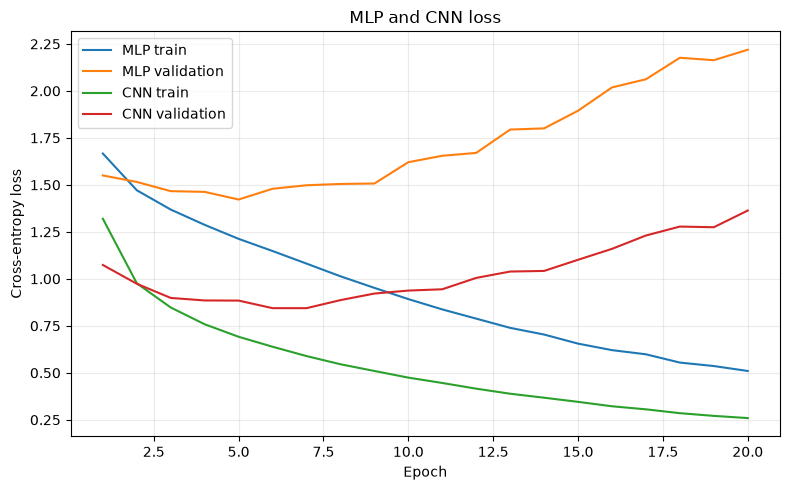

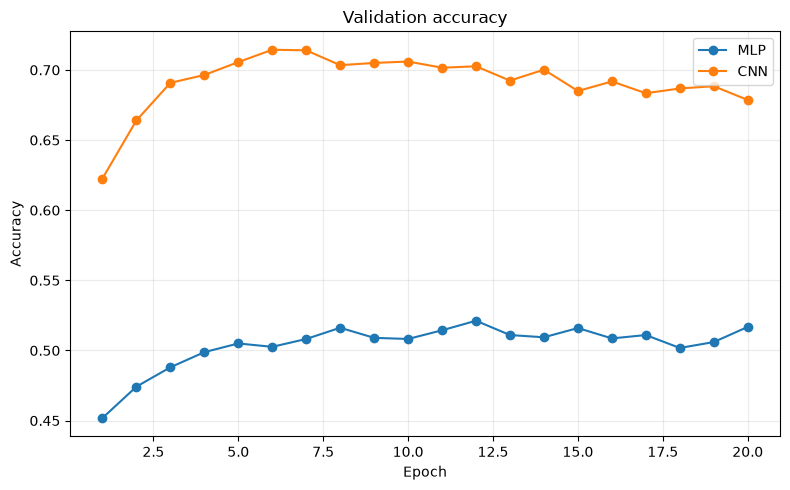

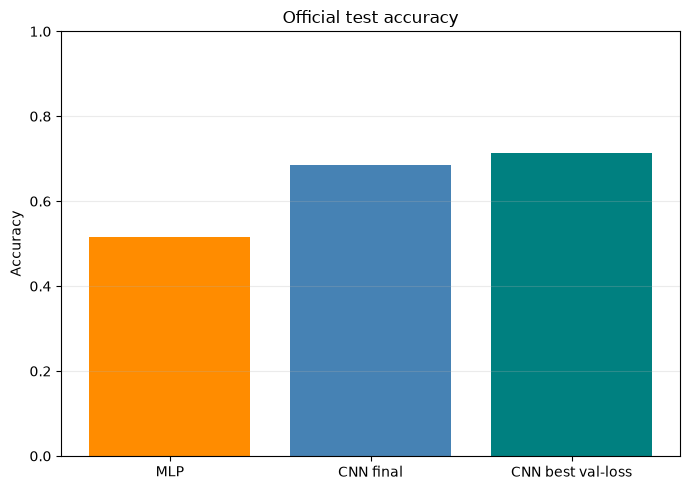

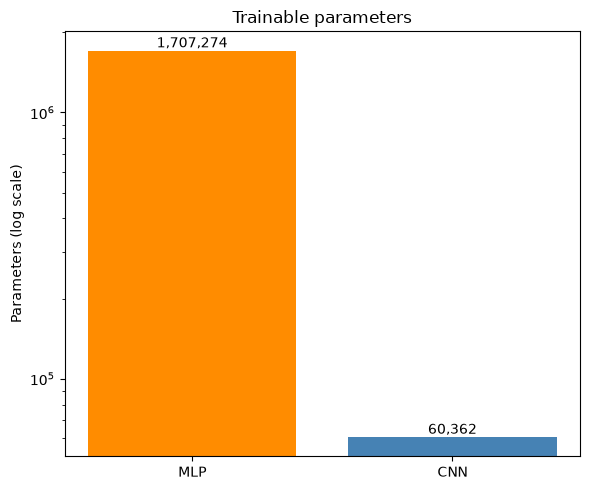

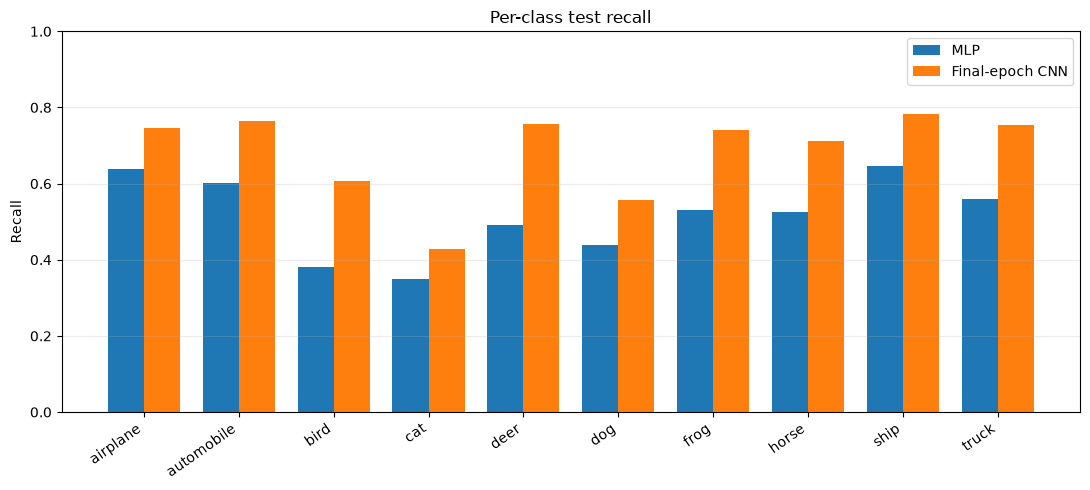

In [8]:
mlp_results_path = PROJECT_ROOT / "artifacts" / "exercise_1" / "results.json"
mlp_results = json.loads(mlp_results_path.read_text(encoding="utf-8"))
mlp_metrics = mlp_results["final_metrics"]
mlp_train_test_gap_pp = 100 * (mlp_metrics["train"]["accuracy"] - mlp_metrics["test"]["accuracy"])
cnn_train_test_gap_pp = 100 * (final_train_accuracy - final_test_accuracy)
best_train_test_gap_pp = 100 * (best_train_accuracy - best_test_accuracy)
parameter_ratio = mlp_results["trainable_parameters"] / TRAINABLE_PARAMETERS
comparison = pd.DataFrame([
    {"model":"MLP", "checkpoint":"Final epoch", "selected_epoch":mlp_results["epochs"],
     "trainable_parameters":mlp_results["trainable_parameters"],
     "train_accuracy":mlp_metrics["train"]["accuracy"], "train_loss":mlp_metrics["train"]["loss"],
     "validation_accuracy":mlp_metrics["validation"]["accuracy"], "validation_loss":mlp_metrics["validation"]["loss"],
     "test_accuracy":mlp_metrics["test"]["accuracy"], "test_loss":mlp_metrics["test"]["loss"],
     "train_test_accuracy_gap_pp":mlp_train_test_gap_pp, "selection_metric":"Final epoch"},
    {"model":"CNN", "checkpoint":"Final epoch", "selected_epoch":EPOCHS,
     "trainable_parameters":TRAINABLE_PARAMETERS,
     "train_accuracy":final_train_accuracy, "train_loss":final_train_loss,
     "validation_accuracy":final_val_accuracy, "validation_loss":final_val_loss,
     "test_accuracy":final_test_accuracy, "test_loss":final_test_loss,
     "train_test_accuracy_gap_pp":cnn_train_test_gap_pp, "selection_metric":"Final epoch"},
    {"model":"CNN", "checkpoint":"Best validation-loss checkpoint", "selected_epoch":best_val_loss_epoch,
     "trainable_parameters":TRAINABLE_PARAMETERS,
     "train_accuracy":best_train_accuracy, "train_loss":best_train_loss,
     "validation_accuracy":best_val_accuracy, "validation_loss":best_val_loss_eval,
     "test_accuracy":best_test_accuracy, "test_loss":best_test_loss,
     "train_test_accuracy_gap_pp":best_train_test_gap_pp, "selection_metric":"Validation loss"},
])
display(comparison)
comparison.to_csv(ARTIFACT_DIR / "mlp_cnn_comparison.csv", index=False)
mlp_history = mlp_results["history"]

fig, ax = plt.subplots(figsize=(8,5))
for key,label in [("train_loss","MLP train"),("val_loss","MLP validation")]:
    ax.plot(range(1,len(mlp_history[key])+1),mlp_history[key],label=label)
for key,label in [("train_loss","CNN train"),("val_loss","CNN validation")]:
    ax.plot(range(1,len(history[key])+1),history[key],label=label)
ax.set(title="MLP and CNN loss",xlabel="Epoch",ylabel="Cross-entropy loss")
ax.legend(); ax.grid(alpha=.25); fig.tight_layout()
fig.savefig(ARTIFACT_DIR/"mlp_cnn_loss_comparison.png",dpi=160); plt.show()

fig,ax=plt.subplots(figsize=(8,5))
ax.plot(range(1,len(mlp_history["val_accuracy"])+1),mlp_history["val_accuracy"],marker="o",label="MLP")
ax.plot(range(1,len(history["val_accuracy"])+1),history["val_accuracy"],marker="o",label="CNN")
ax.set(title="Validation accuracy",xlabel="Epoch",ylabel="Accuracy")
ax.legend(); ax.grid(alpha=.25); fig.tight_layout()
fig.savefig(ARTIFACT_DIR/"mlp_cnn_validation_accuracy.png",dpi=160); plt.show()

fig,ax=plt.subplots(figsize=(7,5))
bar_labels=["MLP","CNN final","CNN best val-loss"]
bar_values=[mlp_metrics["test"]["accuracy"],final_test_accuracy,best_test_accuracy]
ax.bar(bar_labels,bar_values,color=["darkorange","steelblue","teal"])
ax.set(title="Official test accuracy",ylabel="Accuracy",ylim=(0,1)); ax.grid(axis="y",alpha=.25)
fig.tight_layout(); fig.savefig(ARTIFACT_DIR/"mlp_cnn_test_accuracy.png",dpi=160); plt.show()

counts=[mlp_results["trainable_parameters"],TRAINABLE_PARAMETERS]
fig,ax=plt.subplots(figsize=(6,5)); ax.bar(["MLP","CNN"],counts,color=["darkorange","steelblue"])
ax.set_yscale("log"); ax.set(title="Trainable parameters",ylabel="Parameters (log scale)")
for i,value in enumerate(counts): ax.text(i,value,f"{value:,}",ha="center",va="bottom")
fig.tight_layout(); fig.savefig(ARTIFACT_DIR/"mlp_cnn_parameters.png",dpi=160); plt.show()

mlp_recalls=[mlp_results["classification_report"][name]["recall"] for name in CLASS_NAMES]
cnn_recalls=[report[name]["recall"] for name in CLASS_NAMES]
x=np.arange(len(CLASS_NAMES)); width=.38
fig,ax=plt.subplots(figsize=(11,5))
ax.bar(x-width/2,mlp_recalls,width,label="MLP"); ax.bar(x+width/2,cnn_recalls,width,label="Final-epoch CNN")
ax.set_xticks(x,CLASS_NAMES,rotation=35,ha="right")
ax.set(title="Per-class test recall",ylabel="Recall",ylim=(0,1))
ax.legend(); ax.grid(axis="y",alpha=.25); fig.tight_layout()
fig.savefig(ARTIFACT_DIR/"mlp_cnn_class_recall.png",dpi=160); plt.show()

## 10. Discussion

The discussion is generated from the executed measurements. Test results are descriptive and were not used to select a checkpoint.


In [9]:
mlp_test_accuracy = mlp_metrics["test"]["accuracy"]
cnn_test_difference_pp = 100 * (final_test_accuracy - mlp_test_accuracy)
early_stop_gain_pp = 100 * (best_test_accuracy - final_test_accuracy)
cnn_val_loss_min_epoch = int(np.argmin(history["val_loss"]) + 1)
parameter_ratio = mlp_results["trainable_parameters"] / TRAINABLE_PARAMETERS
cnn_train_test_gap_pp = 100 * (final_train_accuracy - final_test_accuracy)
mlp_train_test_gap_pp = 100 * (mlp_metrics["train"]["accuracy"] - mlp_test_accuracy)
cnn_discussion = f"""### Measured comparison

The final-epoch CNN test accuracy was **{final_test_accuracy:.2%}**, compared with **{mlp_test_accuracy:.2%}** for the MLP, a difference of **{cnn_test_difference_pp:+.2f} percentage points (pp)**. The MLP has {mlp_results['trainable_parameters']:,} parameters versus {TRAINABLE_PARAMETERS:,} for the CNN, or **{parameter_ratio:.2f} times** as many. The final-epoch CNN train-to-test accuracy gap was **{cnn_train_test_gap_pp:.2f} pp** (the MLP gap was {mlp_train_test_gap_pp:.2f} pp).

The checkpoint with the lowest validation loss was selected at epoch **{best_val_loss_epoch}**; validation loss bottomed out at **{best_val_loss:.4f}**. That checkpoint reached **{best_test_accuracy:.2%}** test accuracy, a gain of **{early_stop_gain_pp:+.2f} pp** over the final-epoch CNN. Checkpoint selection here uses validation loss, while Exercise 4 reports best validation accuracy. Neither checkpoint was selected using test results.

Convolutions use local receptive fields and share filter weights across image locations. Pooling reduces spatial resolution and gives some tolerance to small shifts. Stacked convolutions can build hierarchical features, from edges to textures and object parts. A flattened MLP has no such built-in spatial structure, despite using more parameters here. This comparison uses one seed, one fixed split, and no data augmentation or regularization."""
display(Markdown(cnn_discussion))

### Measured comparison

The final-epoch CNN test accuracy was **68.50%**, compared with **51.65%** for the MLP, a difference of **+16.85 percentage points (pp)**. The MLP has 1,707,274 parameters versus 60,362 for the CNN, or **28.28 times** as many. The final-epoch CNN train-to-test accuracy gap was **23.59 pp** (the MLP gap was 32.58 pp).

The checkpoint with the lowest validation loss was selected at epoch **7**; validation loss bottomed out at **0.8440**. That checkpoint reached **71.43%** test accuracy, a gain of **+2.93 pp** over the final-epoch CNN. Checkpoint selection here uses validation loss, while Exercise 4 reports best validation accuracy. Neither checkpoint was selected using test results.

Convolutions use local receptive fields and share filter weights across image locations. Pooling reduces spatial resolution and gives some tolerance to small shifts. Stacked convolutions can build hierarchical features, from edges to textures and object parts. A flattened MLP has no such built-in spatial structure, despite using more parameters here. This comparison uses one seed, one fixed split, and no data augmentation or regularization.